# 
Notebook 3 — Modelos Predictivos

## Objetivo
Construir y evaluar modelos `Tiempos = f(...)` para las 8 configuraciones de entrada,
3 ámbitos (Global, por cluster CN, por cluster GA) y múltiples algoritmos ML.

### Configuraciones de modelos
| # | Features | Descripción |
|---|---|---|
| M1 | `DuracionP` | Duración de la tormenta |
| M2 | `VolumenP` | Volumen de lluvia |
| M3 | `MaximoR` | Escorrentía máxima |
| M4 | `MaximoR_VolumenP` | MaxR / VolP |
| M5 | `VolumenR_VolumenP` | VolR / VolP |
| M6 | `MaximoP` | Intensidad máxima de precipitación |
| M7 | `MaximoQ` | Caudal pico |
| M8 | `VolumenP`, `MaximoP` | Lluvia multivariable |

### Algoritmos
- LinearRegression, Ridge
- RandomForest, XGBoost, CatBoost
- SVR (kernel RBF)
- MLP (scikit-learn)

### Métricas hidrológicas
- R², RMSE, MAE
- NSE (Nash-Sutcliffe Efficiency)
- KGE (Kling-Gupta Efficiency)
- PBIAS_% (Percent Bias)
- MAPE_% (Mean Absolute Percentage Error)

### Clusters Predefinidos (Jerárquicos)
**Grupos CN:**
- Cluster 0: FlamisellCabdella, VallfarreraAlins
- Cluster 1: IzalzuAnduña, BailinSabiñanigo, UrriobiEspinal, UbaguaRiezu, ZatoyaOchagavia, ZidacosGarinoiain
- Cluster 2: DezaEmbidDeAriza, GaronaBossost, IsuelaTrasobares, NelaVillarcayo, OroncilloOron, RudronValdelateja, SanguesaOnsella, TironSanMiguelPedroso, TruebaMedinaDePomar, CidacosYanguas, SubialdeLarrinoa

**Grupos GA:**
- Cluster 0: OroncilloOron, FlamisellCabdella, GaronaBossost, TruebaMedinaDePomar
- Cluster 1: IzalzuAnduña, DezaEmbidDeAriza, NelaVillarcayo, RudronValdelateja, SanguesaOnsella, SubialdeLarrinoa, TironSanMiguelPedroso, UrriobiEspinal, UbaguaRiezu, ZatoyaOchagavia, ZidacosGarinoiain, BailinSabiñanigo, IsuelaTrasobares, VallfarreraAlins, CidacosYanguas

### Salidas
- `notebooks/output/3-predictive-models/results_complete.csv`
- `notebooks/output/3-predictive-models/` — figuras

## Imports y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from datetime import datetime
from tqdm import tqdm

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

try:
    from xgboost import XGBRegressor
    XGBOOST_OK = True
except ImportError:
    XGBOOST_OK = False
    print('Warning: XGBoost no disponible')

try:
    from catboost import CatBoostRegressor
    CATBOOST_OK = True
except ImportError:
    CATBOOST_OK = False
    print('Warning: CatBoost no disponible')

warnings.filterwarnings('ignore')

PROC_PATH = '../../data/processed/'
OUT_PATH = '../output/3-predictive-models/'
os.makedirs(OUT_PATH, exist_ok=True)

RANDOM_STATE = 42
N_FOLDS = 5

print('Setup completo.')
print(f'XGBoost disponible: {XGBOOST_OK}')
print(f'CatBoost disponible: {CATBOOST_OK}')

# Sufijo para archivos de salida
file_suffix = "escenario_1_bis_clusters_predefinidos"
print(file_suffix, file_suffix)

Setup completo.
XGBoost disponible: True
CatBoost disponible: True
escenario_4_clusters_predefinidos escenario_4_clusters_predefinidos


## Definición de Clusters Predefinidos

In [2]:
# Clusters CN (jerárquicos) - según instrucciones
CLUSTERS_CN = {
    0: ['FlamisellCabdella', 'VallfarreraAlins'],
    1: ['IzalzuAnduña', 'BailinSabiñanigo', 'UrriobiEspinal', 
        'UbaguaRiezu', 'ZatoyaOchagavia', 'ZidacosGarinoiain'],
    2: ['DezaEmbidDeAriza', 'GaronaBossost', 'IsuelaTrasobares', 
        'NelaVillarcayo', 'OroncilloOron', 'RudronValdelateja', 
        'SanguesaOnsella', 'TironSanMiguelPedroso', 'TruebaMedinaDePomar', 
        'CidacosYanguas', 'SubialdeLarrinoa']
}

# Clusters GA - según instrucciones
CLUSTERS_GA = {
    0: ['OroncilloOron', 'FlamisellCabdella', 'GaronaBossost', 'TruebaMedinaDePomar'],
    1: ['IzalzuAnduña', 'DezaEmbidDeAriza', 'NelaVillarcayo', 'RudronValdelateja', 
        'SanguesaOnsella', 'SubialdeLarrinoa', 'TironSanMiguelPedroso', 
        'UrriobiEspinal', 'UbaguaRiezu', 'ZatoyaOchagavia', 'ZidacosGarinoiain',
        'BailinSabiñanigo', 'IsuelaTrasobares', 'VallfarreraAlins', 'CidacosYanguas']
}

# Mapeo de nombres cortos a nombres completos de cuencas
CUENCA_MAP = {
    'Anduña': 'IzalzuAnduña',
    'Bailin': 'BailinSabiñanigo',
    'Deza': 'DezaEmbidDeAriza',
    'Flamisell': 'FlamisellCabdella',
    'Garona': 'GaronaBossost',
    'Isuela': 'IsuelaTrasobares',
    'Nela': 'NelaVillarcayo',
    'Oroncillo': 'OroncilloOron',
    'Rudron': 'RudronValdelateja',
    'Sangüesa': 'SanguesaOnsella',
    'Subialde': 'SubialdeLarrinoa',
    'Tiron': 'TironSanMiguelPedroso',
    'Trueba': 'TruebaMedinaDePomar',
    'Ubagua': 'UbaguaRiezu',
    'Urrobi': 'UrriobiEspinal',
    'Vallfarrera': 'VallfarreraAlins',
    'Yanguas': 'CidacosYanguas',
    'Zatoya': 'ZatoyaOchagavia',
    'Zidacos': 'ZidacosGarinoiain'
}

# Crear mapeo inverso: cuenca completa -> cluster CN/GA
def create_cluster_map(clusters_dict):
    mapping = {}
    for cluster_id, cuencas in clusters_dict.items():
        for cuenca in cuencas:
            mapping[cuenca] = cluster_id
    return mapping

CN_MAP = create_cluster_map(CLUSTERS_CN)
GA_MAP = create_cluster_map(CLUSTERS_GA)

print(f'Clusters CN definidos: {len(CLUSTERS_CN)} clusters')
for k, v in CLUSTERS_CN.items():
    print(f"  Cluster {k}: {len(v)} cuencas")

print(f'\nClusters GA definidos: {len(CLUSTERS_GA)} clusters')
for k, v in CLUSTERS_GA.items():
    print(f"  Cluster {k}: {len(v)} cuencas")

Clusters CN definidos: 3 clusters
  Cluster 0: 2 cuencas
  Cluster 1: 6 cuencas
  Cluster 2: 11 cuencas

Clusters GA definidos: 2 clusters
  Cluster 0: 4 cuencas
  Cluster 1: 15 cuencas


## Métricas Hidrológicas

In [3]:
def nse(y_true, y_pred):
    """Nash-Sutcliffe Efficiency. Optimo=1, >0 mejor que la media."""
    num = np.sum((np.array(y_true) - np.array(y_pred)) ** 2)
    den = np.sum((np.array(y_true) - np.mean(y_true)) ** 2)
    return float(1 - num / den) if den > 0 else np.nan

def kge(y_true, y_pred):
    """Kling-Gupta Efficiency. Optimo=1."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    r = np.corrcoef(y_true, y_pred)[0, 1]
    alpha = np.std(y_pred) / (np.std(y_true) + 1e-12)
    beta = np.mean(y_pred) / (np.mean(y_true) + 1e-12)
    return float(1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2))

def pbias_pct(y_true, y_pred):
    """Percent Bias (%). Optimo=0, <0 sobreestima, >0 subestima."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    denom = np.sum(np.abs(y_true))
    return float(100 * np.sum(y_true - y_pred) / denom) if denom > 0 else np.nan

def mape_pct(y_true, y_pred):
    """Mean Absolute Percentage Error (%)."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = np.abs(y_true) > 1e-9
    return float(100 * np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]))) if mask.sum() > 0 else np.nan

def compute_metrics(y_true, y_pred):
    """Dict con R2, RMSE, MAE, NSE, KGE, PBIAS_pct, MAPE_pct."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return {
        'R2': float(r2_score(y_true, y_pred)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'NSE': nse(y_true, y_pred),
        'KGE': kge(y_true, y_pred),
        'PBIAS_pct': pbias_pct(y_true, y_pred),
        'MAPE_pct': mape_pct(y_true, y_pred),
    }

print('Metricas definidas: R2, RMSE, MAE, NSE, KGE, PBIAS_pct, MAPE_pct')

Metricas definidas: R2, RMSE, MAE, NSE, KGE, PBIAS_pct, MAPE_pct


## Definición de Algoritmos ML

In [4]:
def get_models():
    """Devuelve dict {nombre: pipeline}."""
    models = {
        'LinearRegression': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LinearRegression())
        ]),
        'Ridge': Pipeline([
            ('scaler', StandardScaler()),
            ('model', Ridge(alpha=1.0))
        ]),
        'RandomForest': Pipeline([
            ('scaler', StandardScaler()),
            ('model', RandomForestRegressor(
                n_estimators=200, max_depth=None,
                min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
            ))
        ]),
        'SVR (RBF)': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVR(kernel='rbf', C=10.0, epsilon=0.1, gamma='scale'))
        ]),
        'MLP': Pipeline([
            ('scaler', StandardScaler()),
            ('model', MLPRegressor(
                hidden_layer_sizes=(64, 32), activation='relu',
                max_iter=500, random_state=RANDOM_STATE, early_stopping=True
            ))
        ]),
    }
    
    if XGBOOST_OK:
        models['XGBoost'] = Pipeline([
            ('scaler', StandardScaler()),
            ('model', XGBRegressor(
                n_estimators=200, learning_rate=0.05, max_depth=5,
                subsample=0.8, colsample_bytree=0.8,
                random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
            ))
        ])
    
    if CATBOOST_OK:
        models['CatBoost'] = Pipeline([
            ('scaler', StandardScaler()),
            ('model', CatBoostRegressor(
                iterations=200, learning_rate=0.05, depth=5,
                random_state=RANDOM_STATE, verbose=0
            ))
        ])
    
    return models

MODEL_NAMES = list(get_models().keys())
print(f'Algoritmos configurados ({len(MODEL_NAMES)}): {MODEL_NAMES}')

Algoritmos configurados (7): ['LinearRegression', 'Ridge', 'RandomForest', 'SVR (RBF)', 'MLP', 'XGBoost', 'CatBoost']


## Configuraciones de Modelos

In [5]:
MODEL_SPECS = [
    {'id': 'M1', 'features': ['DuracionP'], 'descripcion': 'Tiempos=f(Duración de la tormenta)'},
    {'id': 'M2', 'features': ['VolumenP'], 'descripcion': 'Tiempos = f(Volumen de Lluvia)'},
    {'id': 'M3', 'features': ['MaximoR'], 'descripcion': 'Tiempos = f(Escorrentía Máxima)'},
    {'id': 'M4', 'features': ['MaximoR_VolumenP'], 'descripcion': 'Tiempos = f(Escorrentía Máxima / Volumen de Lluvia)'},
    {'id': 'M5', 'features': ['VolumenR_VolumenP'], 'descripcion': 'Tiempos = f(Volumen Escorrentía / Volumen de Lluvia)'},
    {'id': 'M6', 'features': ['MaximoP'], 'descripcion': 'Tiempos = f(Intensidad Máxima de Precipitación)'},
    {'id': 'M7', 'features': ['MaximoQ'], 'descripcion': 'Tiempos = f(Caudal Pico)'},
    {'id': 'M8', 'features': ['VolumenP', 'MaximoP'], 'descripcion': 'Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)'},
]

print(f'Configuraciones: {len(MODEL_SPECS)}')
for m in MODEL_SPECS:
    print(f"  {m['id']}: {m['descripcion']}  features={m['features']}")

Configuraciones: 8
  M1: Tiempos=f(Duración de la tormenta)  features=['DuracionP']
  M2: Tiempos = f(Volumen de Lluvia)  features=['VolumenP']
  M3: Tiempos = f(Escorrentía Máxima)  features=['MaximoR']
  M4: Tiempos = f(Escorrentía Máxima / Volumen de Lluvia)  features=['MaximoR_VolumenP']
  M5: Tiempos = f(Volumen Escorrentía / Volumen de Lluvia)  features=['VolumenR_VolumenP']
  M6: Tiempos = f(Intensidad Máxima de Precipitación)  features=['MaximoP']
  M7: Tiempos = f(Caudal Pico)  features=['MaximoQ']
  M8: Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)  features=['VolumenP', 'MaximoP']


## Carga de Datos

In [6]:
# Cargar dataset desde CSV procesado
df_raw = pd.read_csv(os.path.join(PROC_PATH, 'events_dataset.csv'))

print(f'Dataset cargado: {df_raw.shape}')
print(f'Columnas: {df_raw.columns.tolist()}')
print(f'\nCuencas en dataset: {sorted(df_raw["cuenca"].unique())}')

# Mapear nombres de cuencas cortos a completos
df_raw['cuenca_completa'] = df_raw['cuenca'].map(CUENCA_MAP)

# Asignar clusters predefinidos
df_raw['cluster_cn'] = df_raw['cuenca_completa'].map(CN_MAP)
df_raw['cluster_ga'] = df_raw['cuenca_completa'].map(GA_MAP)

print(f'\nClusters CN asignados: {sorted(df_raw["cluster_cn"].dropna().unique())}')
print(f'Clusters GA asignados: {sorted(df_raw["cluster_ga"].dropna().unique())}')

Dataset cargado: (23118, 14)
Columnas: ['cuenca', 'cuenca_larga', 'evento_id', 'tiempos', 'duracion_p', 'duracion_q', 'maximo_p', 'maximo_q', 'maximo_r', 'volumen_p', 'volumen_q', 'volumen_r', 'ratio_r_p', 'ratio_vr_vp']

Cuencas en dataset: ['Anduña', 'Bailin', 'Deza', 'Espinal', 'Flamisell', 'Garona', 'Isuela', 'Nela', 'Onsella', 'Oroncillo', 'Rudron', 'Subialde', 'Tiron', 'Trueba', 'Ubagua', 'Vallfarrera', 'Yanguas', 'Zatoya', 'Zidacos']

Clusters CN asignados: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
Clusters GA asignados: [np.float64(0.0), np.float64(1.0)]


In [7]:
# Renombrar columnas snake_case a PascalCase para compatibilidad con MODEL_SPECS
df_all = df_raw.rename(columns={
    'tiempos': 'Tiempos',
    'duracion_p': 'DuracionP',
    'duracion_q': 'DuracionQ',
    'maximo_p': 'MaximoP',
    'maximo_q': 'MaximoQ',
    'maximo_r': 'MaximoR',
    'volumen_p': 'VolumenP',
    'volumen_q': 'VolumenQ',
    'volumen_r': 'VolumenR',
    'ratio_r_p': 'RatioR_P',
    'ratio_vr_vp': 'VolumenR_VolumenP'
}).copy()

# Crear feature derivada MaximoR_VolumenP (ratio escorrentía máxima / volumen lluvia)
df_all['MaximoR_VolumenP'] = df_all['MaximoR'] / (df_all['VolumenP'] + 1e-12)

print(f'\nDataset preparado: {df_all.shape}')
print(f'Total eventos: {len(df_all):,}')
print(f'\nPrimeras filas:')
display(df_all[['cuenca', 'evento_id', 'Tiempos', 'DuracionP', 'VolumenP', 
                'MaximoR', 'MaximoR_VolumenP', 'cluster_cn', 'cluster_ga']].head())


Dataset preparado: (23118, 18)
Total eventos: 23,118

Primeras filas:


,cuenca,evento_id,Tiempos,DuracionP,VolumenP,MaximoR,MaximoR_VolumenP,cluster_cn,cluster_ga
0,Bailin,0,0.5,0.5,9016.4,1127.05,0.125,1.0,1.0
1,Bailin,2,120.5,120.5,4508.2,1127.05,0.250,1.0,1.0
2,Bailin,4,80.5,80.5,9016.4,1127.05,0.125,1.0,1.0
3,Bailin,5,0.5,0.5,9016.4,1127.05,0.125,1.0,1.0
4,Bailin,7,2.0,2.0,4508.2,1127.05,0.250,1.0,1.0


## Función de Entrenamiento con K-Fold CV

In [8]:
def train_and_evaluate(df_subset, feature_cols, target_col='Tiempos',
                       model_pipeline=None, n_folds=5):
    """
    K-Fold CV y devuelve metricas promedio.
    """
    df_valid = df_subset[[target_col] + feature_cols].dropna()
    
    if len(df_valid) < n_folds * 2:
        return {
            'n_samples': len(df_valid),
            'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan,
            'NSE': np.nan, 'KGE': np.nan, 'PBIAS_pct': np.nan, 'MAPE_pct': np.nan,
            'error': 'insufficient_data'
        }
    
    X = df_valid[feature_cols].values
    y = df_valid[target_col].values
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    metrics_per_fold = []
    
    for train_idx, val_idx in kf.split(X):
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        model_pipeline.fit(X_tr, y_tr)
        y_pred = model_pipeline.predict(X_val)
        metrics_per_fold.append(compute_metrics(y_val, y_pred))
    
    avg = {k: float(np.nanmean([m[k] for m in metrics_per_fold])) for k in metrics_per_fold[0]}
    avg['n_samples'] = len(df_valid)
    return avg

print('Función de entrenamiento definida.')

Función de entrenamiento definida.


## Construcción de Ámbitos de Datos

In [9]:
scopes = {}
scopes['Global'] = df_all.copy()

# Clusters CN
for c in sorted(df_all['cluster_cn'].dropna().unique()):
    label = f'CN_Cluster{int(c)}'
    scopes[label] = df_all[df_all['cluster_cn'] == c].copy()

# Clusters GA
for c in sorted(df_all['cluster_ga'].dropna().unique()):
    label = f'GA_Cluster{int(c)}'
    scopes[label] = df_all[df_all['cluster_ga'] == c].copy()

print('Ambitos de entrenamiento:')
for label, subset in scopes.items():
    print(f'  {label:20s}: {len(subset):,} eventos')

Ambitos de entrenamiento:
  Global              : 23,118 eventos
  CN_Cluster0         : 2,297 eventos
  CN_Cluster1         : 4,817 eventos
  CN_Cluster2         : 13,334 eventos
  GA_Cluster0         : 6,053 eventos
  GA_Cluster1         : 14,395 eventos


## Ejecución de Modelos

Se entrenarán todos los modelos según las especificaciones del template CSV.

In [10]:
list(get_models().items())[0]

('LinearRegression',
 Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())]))

In [11]:
all_results = []

# Contar total de modelos a ejecutar
total_count = 0
for spec in MODEL_SPECS:
    for scope_label in scopes.keys():
        total_count += len(MODEL_NAMES)

print(f'Total combinaciones a ejecutar: {total_count}')
print(f'  {len(MODEL_SPECS)} configs × {len(scopes)} ámbitos × {len(MODEL_NAMES)} algoritmos')
print('\nEjecutando modelos...')

pbar = tqdm(total=total_count, desc='Modelos')

for spec in MODEL_SPECS:
    for scope_label, df_scope in scopes.items():
        for model_name, model_pipeline in get_models().items():
            #print(f"Executing: {model_name}, {model_pipeline}")
            result = train_and_evaluate(
                df_subset=df_scope,
                feature_cols=spec['features'],
                target_col='Tiempos',
                model_pipeline=model_pipeline,
                n_folds=N_FOLDS
            )
            
            record = {
                'Config': spec['id'],
                'Descripción': spec['descripcion'],
                'Features': ', '.join(spec['features']),
                'Ámbito': scope_label,
                'Algoritmo': model_name,
                'n_samples': result.get('n_samples', 0),
                'R²': result.get('R2', np.nan),
                'RMSE': result.get('RMSE', np.nan),
                'MAE': result.get('MAE', np.nan),
                'NSE': result.get('NSE', np.nan),
                'KGE': result.get('KGE', np.nan),
                'PBIAS_%': result.get('PBIAS_pct', np.nan),
                'MAPE_%': result.get('MAPE_pct', np.nan),
            }
            all_results.append(record)
            pbar.update(1)

pbar.close()

results_df = pd.DataFrame(all_results)
print(f'\n✓ Resultados completos: {results_df.shape}')
display(results_df.head(10))

Total combinaciones a ejecutar: 336
  8 configs × 6 ámbitos × 7 algoritmos

Ejecutando modelos...


Modelos: 100%|███| 336/336 [14:37<00:00,  2.61s/it]


✓ Resultados completos: (336, 13)


,Config,Descripción,Features,Ámbito,Algoritmo,n_samples,R²,RMSE,MAE,NSE,KGE,PBIAS_%,MAPE_%
0,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,LinearRegression,23118,1.000000,3.234624e-12,2.459465e-12,1.000000,1.000000,5.430760e-15,5.333735e-11
1,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,Ridge,23118,1.000000,1.237748e-02,9.442506e-03,1.000000,0.999946,-1.233735e-06,2.075720e-01
2,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,RandomForest,23118,0.999996,4.312879e-01,3.277860e-02,0.999996,0.999872,-2.015871e-03,6.982256e-03
3,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,SVR (RBF),23118,0.992523,1.858320e+01,9.962586e-01,0.992523,0.982074,4.819561e-01,3.923331e+00
4,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,MLP,23118,0.999994,5.408662e-01,3.407798e-01,0.999994,0.999723,-2.253040e-02,2.644113e+01
5,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,XGBoost,23118,0.997796,1.035220e+01,1.667810e+00,0.997796,0.996407,3.125458e-02,1.099262e+00
6,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,CatBoost,23118,0.997788,1.039624e+01,2.713984e+00,0.997788,0.996600,2.108102e-02,9.809840e+00
7,M1,Tiempos=f(Duración de la tormenta),DuracionP,CN_Cluster0,LinearRegression,2297,1.000000,3.883560e-13,3.167606e-13,1.000000,1.000000,6.321778e-15,8.230731e-12
8,M1,Tiempos=f(Duración de la tormenta),DuracionP,CN_Cluster0,Ridge,2297,1.000000,1.319779e-01,1.082759e-01,1.000000,0.999454,-2.892620e-04,2.692849e+00
9,M1,Tiempos=f(Duración de la tormenta),DuracionP,CN_Cluster0,RandomForest,2297,0.999980,9.993575e-01,1.350947e-01,0.999980,0.999267,3.673329e-03,5.513218e-02


## Análisis de Resultados — Global

In [12]:
df_global = results_df[results_df['Ámbito'] == 'Global'].copy()

pivot_nse = df_global.pivot_table(
    index=['Config', 'Descripción'],
    columns='Algoritmo',
    values='NSE'
).round(3)

print('NSE por modelo y algoritmo (ámbito Global):')
display(pivot_nse)

pivot_kge = df_global.pivot_table(
    index=['Config', 'Descripción'],
    columns='Algoritmo',
    values='KGE'
).round(3)

print('\nKGE por modelo y algoritmo (ámbito Global):')
display(pivot_kge)

NSE por modelo y algoritmo (ámbito Global):


,Algoritmo,CatBoost,LinearRegression,MLP,RandomForest,Ridge,SVR (RBF),XGBoost
Config,Descripción,,,,,,,
M1,Tiempos=f(Duración de la tormenta),0.998,1.000,1.000,1.000,1.000,0.993,0.998
M2,Tiempos = f(Volumen de Lluvia),0.198,0.050,0.063,0.255,0.050,0.002,0.211
M3,Tiempos = f(Escorrentía Máxima),0.139,0.035,0.088,0.229,0.035,-0.016,0.173
M4,Tiempos = f(Escorrentía Máxima / Volumen de Lluvia),0.006,0.000,0.000,0.010,0.000,-0.162,0.007
M5,Tiempos = f(Volumen Escorrentía / Volumen de Lluvia),0.001,0.001,0.001,0.001,0.001,-0.161,0.001
M6,Tiempos = f(Intensidad Máxima de Precipitación),0.231,0.056,0.128,0.250,0.056,0.036,0.249
M7,Tiempos = f(Caudal Pico),0.116,0.008,0.012,0.472,0.008,-0.131,0.178
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)",0.238,0.060,0.130,0.265,0.060,0.038,0.250



KGE por modelo y algoritmo (ámbito Global):


,Algoritmo,CatBoost,LinearRegression,MLP,RandomForest,Ridge,SVR (RBF),XGBoost
Config,Descripción,,,,,,,
M1,Tiempos=f(Duración de la tormenta),0.997,1.000,1.000,1.000,1.000,0.982,0.996
M2,Tiempos = f(Volumen de Lluvia),0.173,-0.096,-0.064,0.308,-0.096,-0.118,0.231
M3,Tiempos = f(Escorrentía Máxima),0.081,-0.148,0.007,0.283,-0.148,-0.139,0.154
M4,Tiempos = f(Escorrentía Máxima / Volumen de Lluvia),-0.315,-0.375,-0.366,-0.217,-0.375,-0.463,-0.284
M5,Tiempos = f(Volumen Escorrentía / Volumen de Lluvia),-0.351,-0.357,-0.348,-0.350,-0.357,-0.451,-0.350
M6,Tiempos = f(Intensidad Máxima de Precipitación),0.231,-0.080,0.087,0.295,-0.080,-0.065,0.290
M7,Tiempos = f(Caudal Pico),0.009,-0.287,-0.256,0.572,-0.287,-0.318,0.138
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)",0.237,-0.068,0.093,0.322,-0.068,-0.057,0.284


In [13]:
# Mejor algoritmo por modelo (Global)
best_global = df_global.sort_values('NSE', ascending=False).groupby('Config').first()
print('Mejor algoritmo por configuración (Global, ordenado por NSE):')
display(best_global[['Descripción', 'Algoritmo', 'n_samples',
                      'R²', 'RMSE', 'MAE', 'NSE', 'KGE', 'PBIAS_%', 'MAPE_%']].round(3))

Mejor algoritmo por configuración (Global, ordenado por NSE):


,Descripción,Algoritmo,n_samples,R²,RMSE,MAE,NSE,KGE,PBIAS_%,MAPE_%
Config,,,,,,,,,,
M1,Tiempos=f(Duración de la tormenta),LinearRegression,23118,1.000,0.000,0.000,1.000,1.000,0.000,0.000
M2,Tiempos = f(Volumen de Lluvia),RandomForest,23118,0.255,197.549,138.252,0.255,0.308,-0.166,1522.817
M3,Tiempos = f(Escorrentía Máxima),RandomForest,23118,0.229,201.004,140.879,0.229,0.283,-0.156,1588.736
M4,Tiempos = f(Escorrentía Máxima / Volumen de Ll...,RandomForest,23118,0.010,227.780,171.674,0.010,-0.217,-0.346,3629.531
M5,Tiempos = f(Volumen Escorrentía / Volumen de L...,CatBoost,23118,0.001,228.744,174.373,0.001,-0.351,-0.034,3799.089
M6,Tiempos = f(Intensidad Máxima de Precipitación),RandomForest,23118,0.250,198.282,139.108,0.250,0.295,-0.075,1558.770
M7,Tiempos = f(Caudal Pico),RandomForest,23118,0.472,166.285,107.251,0.472,0.572,0.053,1087.152
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxi...",RandomForest,23118,0.265,196.168,137.261,0.265,0.322,-0.110,1522.454


## Análisis de Resultados — Por Cluster

In [14]:
df_cn = results_df[results_df['Ámbito'].str.contains('CN')].copy()
if not df_cn.empty:
    pivot_cn = df_cn.pivot_table(
        index=['Ámbito', 'Config', 'Descripción'],
        columns='Algoritmo', values='NSE'
    ).round(3)
    print('NSE por cluster CN, modelo y algoritmo:')
    display(pivot_cn)

df_ga = results_df[results_df['Ámbito'].str.contains('GA')].copy()
if not df_ga.empty:
    pivot_ga = df_ga.pivot_table(
        index=['Ámbito', 'Config', 'Descripción'],
        columns='Algoritmo', values='NSE'
    ).round(3)
    print('\nNSE por cluster GA, modelo y algoritmo:')
    display(pivot_ga)

NSE por cluster CN, modelo y algoritmo:


Algoritmo                                                              CatBoost  \
Ámbito      Config Descripción                                                    
CN_Cluster0 M1     Tiempos=f(Duración de la tormenta)                     1.000   
            M2     Tiempos = f(Volumen de Lluvia)                         0.007   
            M3     Tiempos = f(Escorrentía Máxima)                       -0.017   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...    -0.024   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...    -0.012   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)       -0.002   
            M7     Tiempos = f(Caudal Pico)                               0.220   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...     0.010   
CN_Cluster1 M1     Tiempos=f(Duración de la tormenta)                     1.000   
            M2     Tiempos = f(Volumen de Lluvia)                         0.408   
            M3     Tiempos = f(Escorrentía Máxima)                        0.317   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...     0.023   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...    -0.004   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)        0.396   
            M7     Tiempos = f(Caudal Pico)                               0.408   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...     0.432   
CN_Cluster2 M1     Tiempos=f(Duración de la tormenta)                     1.000   
            M2     Tiempos = f(Volumen de Lluvia)                         0.189   
            M3     Tiempos = f(Escorrentía Máxima)                        0.166   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...     0.009   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...    -0.000   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)        0.204   
            M7     Tiempos = f(Caudal Pico)                               0.134   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...     0.209   

Algoritmo                                                              LinearRegression  \
Ámbito      Config Descripción                                                            
CN_Cluster0 M1     Tiempos=f(Duración de la tormenta)                             1.000   
            M2     Tiempos = f(Volumen de Lluvia)                                -0.001   
            M3     Tiempos = f(Escorrentía Máxima)                               -0.007   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...            -0.006   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...            -0.007   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)               -0.003   
            M7     Tiempos = f(Caudal Pico)                                       0.006   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...            -0.002   
CN_Cluster1 M1     Tiempos=f(Duración de la tormenta)                             1.000   
            M2     Tiempos = f(Volumen de Lluvia)                                 0.155   
            M3     Tiempos = f(Escorrentía Máxima)                                0.103   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...             0.015   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...            -0.001   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)                0.157   
            M7     Tiempos = f(Caudal Pico)                                       0.063   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...             0.190   
CN_Cluster2 M1     Tiempos=f(Duración de la tormenta)                             1.000   
            M2     Tiempos = f(Volumen de Lluvia)                                 0.052   
            M3     Ti


NSE por cluster GA, modelo y algoritmo:


Algoritmo                                                              CatBoost  \
Ámbito      Config Descripción                                                    
GA_Cluster0 M1     Tiempos=f(Duración de la tormenta)                     1.000   
            M2     Tiempos = f(Volumen de Lluvia)                         0.184   
            M3     Tiempos = f(Escorrentía Máxima)                        0.162   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...     0.007   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...    -0.002   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)        0.176   
            M7     Tiempos = f(Caudal Pico)                               0.276   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...     0.186   
GA_Cluster1 M1     Tiempos=f(Duración de la tormenta)                     1.000   
            M2     Tiempos = f(Volumen de Lluvia)                         0.208   
            M3     Tiempos = f(Escorrentía Máxima)                        0.166   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...     0.002   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...     0.001   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)        0.233   
            M7     Tiempos = f(Caudal Pico)                               0.159   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...     0.241   

Algoritmo                                                              LinearRegression  \
Ámbito      Config Descripción                                                            
GA_Cluster0 M1     Tiempos=f(Duración de la tormenta)                             1.000   
            M2     Tiempos = f(Volumen de Lluvia)                                 0.127   
            M3     Tiempos = f(Escorrentía Máxima)                                0.078   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...             0.006   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...             0.000   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)                0.130   
            M7     Tiempos = f(Caudal Pico)                                       0.066   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...             0.141   
GA_Cluster1 M1     Tiempos=f(Duración de la tormenta)                             1.000   
            M2     Tiempos = f(Volumen de Lluvia)                                 0.053   
            M3     Tiempos = f(Escorrentía Máxima)                                0.035   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...            -0.001   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll...             0.001   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)                0.056   
            M7     Tiempos = f(Caudal Pico)                                       0.006   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...             0.062   

Algoritmo                                                                MLP  \
Ámbito      Config Descripción                                                 
GA_Cluster0 M1     Tiempos=f(Duración de la tormenta)                  0.999   
            M2     Tiempos = f(Volumen de Lluvia)                      0.127   
            M3     Tiempos = f(Escorrentía Máxima)                     0.093   
            M4     Tiempos = f(Escorrentía Máxima / Volumen de Llu...  0.007   
            M5     Tiempos = f(Volumen Escorrentía / Volumen de Ll... -0.000   
            M6     Tiempos = f(Intensidad Máxima de Precipitación)     0.158   
            M7     Tiempos = f(Caudal Pico)                            0.080   
            M8     Tiempos = f(Volumen de Lluvia, Intensidad Máxim...  0.168   
GA_Cluster1 M1     Tiempos=f(Duración de la tormenta)             

## Visualización: Heatmap NSE/KGE (Global)

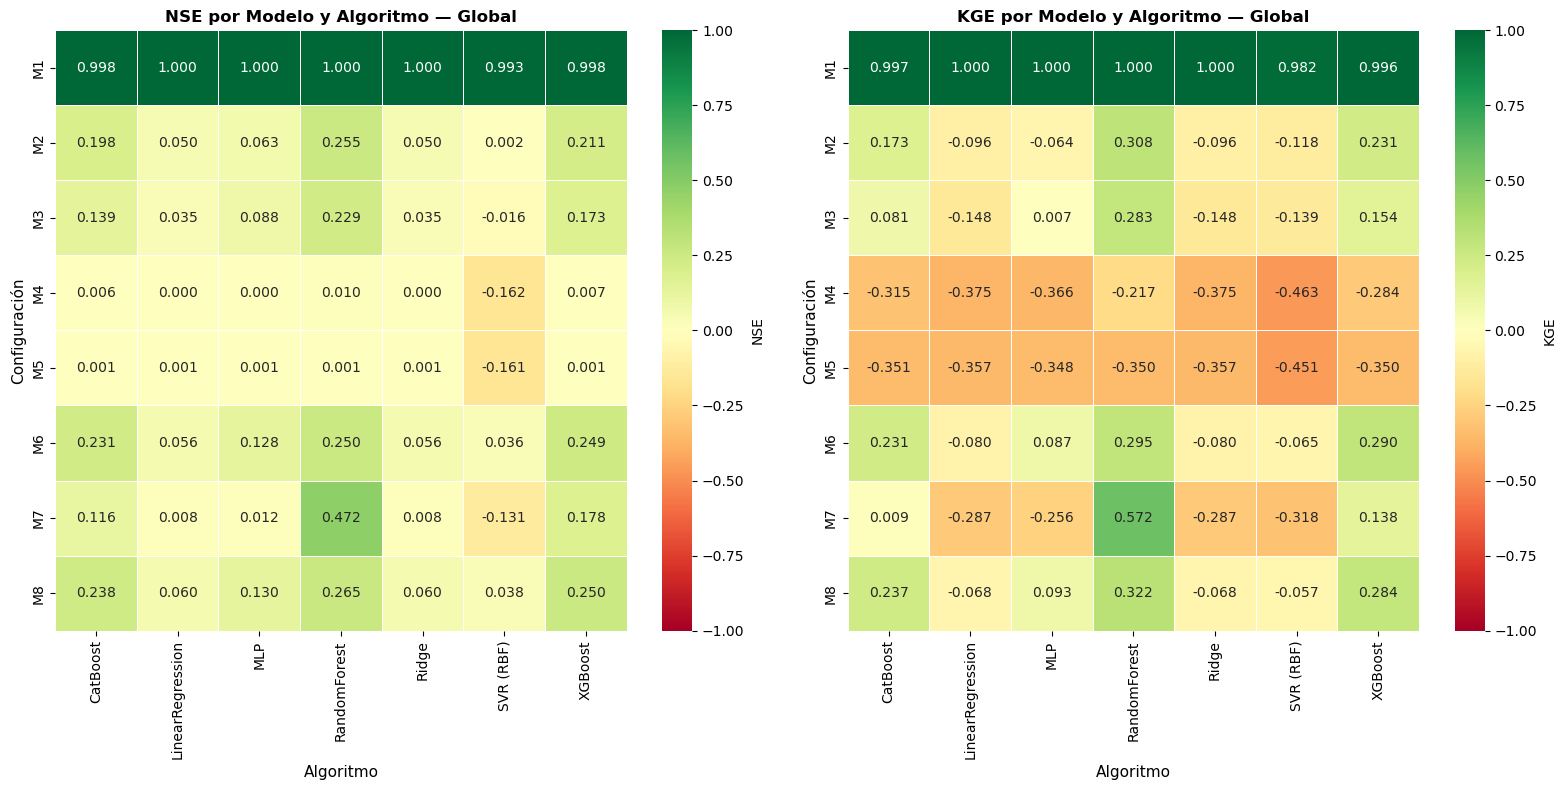

✓ Figura guardada: heatmap_nse_kge_global.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, metric in zip(axes, ['NSE', 'KGE']):
    hm = df_global.pivot_table(index='Config', columns='Algoritmo', values=metric).round(3)
    sns.heatmap(hm, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
                vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={'label': metric})
    ax.set_title(f'{metric} por Modelo y Algoritmo — Global', fontsize=12, weight='bold')
    ax.set_ylabel('Configuración', fontsize=11)
    ax.set_xlabel('Algoritmo', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUT_PATH, 'heatmap_nse_kge_global.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✓ Figura guardada: heatmap_nse_kge_global.png')

## Guardar Resultados Completos

In [16]:
# Guardar resultados completos
results_df['Num.'] = range(1, len(results_df) + 1)

# Reordenar columnas para coincidir con template
results_output = results_df[[
    'Num.', 'Config', 'Descripción', 'Features', 'Ámbito', 'Algoritmo',
    'R²', 'RMSE', 'MAE', 'NSE', 'KGE', 'PBIAS_%', 'MAPE_%', 'n_samples'
]].copy()

# Guardar con timestamp
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
csv_path = os.path.join(OUT_PATH, f'results_complete_{file_suffix}_{timestamp}.csv')
results_output.to_csv(csv_path, index=False, sep=';', encoding='utf-8')
print(f'✓ Tabla completa guardada en: {csv_path}')

# Guardar también en formato template (sin timestamp)
template_path = os.path.join(OUT_PATH, f'results_complete_{file_suffix}.csv')
results_output.to_csv(template_path, index=False, sep=';', encoding='utf-8')
print(f'✓ Resultados guardados en formato template: {template_path}')

print(f'\nTotal de modelos ejecutados: {len(results_output)}')
print(f'\nResumen de métricas promedio por algoritmo:')
display(results_df.groupby('Algoritmo')[['R²', 'RMSE', 'NSE', 'KGE', 'PBIAS_%']].mean().round(3))

✓ Tabla completa guardada en: ../output/3-predictive-models/results_complete_escenario_4_clusters_predefinidos_20260305_222350.csv
✓ Resultados guardados en formato template: ../output/3-predictive-models/results_complete_escenario_4_clusters_predefinidos.csv

Total de modelos ejecutados: 336

Resumen de métricas promedio por algoritmo:


,R²,RMSE,NSE,KGE,PBIAS_%
Algoritmo,,,,,
CatBoost,0.250,177.356,0.250,0.139,-0.148
LinearRegression,0.164,186.951,0.164,-0.021,-0.165
MLP,0.179,185.815,0.179,0.021,0.469
RandomForest,0.289,171.495,0.289,0.223,-0.157
Ridge,0.164,186.957,0.164,-0.021,-0.165
SVR (RBF),0.106,194.635,0.106,-0.035,30.041
XGBoost,0.267,175.003,0.267,0.179,-0.107


## Resumen Final

Los modelos han sido ejecutados con:
- **Clusters predefinidos** (jerárquicos) según instrucciones
- **8 configuraciones** de modelos (M1-M8)
- **3 ámbitos**: Global, Cluster CN, Cluster GA
- **Múltiples algoritmos**: LinearRegression, Ridge, RandomForest, XGBoost, CatBoost, SVR, MLP
- **7 métricas**: R², RMSE, MAE, NSE, KGE, PBIAS%, MAPE%

Los resultados se han guardado en `notebooks/output/3-predictive-models/results_complete.csv`